# 04 - Real AI4I 2020 dataset par comparison
Synthetic dataset ke saath saath real **AI4I 2020 Predictive Maintenance** dataset par bhi wahi pipeline chalayi.

> AI4I me `machine_id` aur `timestamp` nahi hota (har row independent sample hai). `src/import_ai4i.py` rows ko order me hourly timestamp deta hai aur har 200 rows ko ek machine maanta hai. Isliye **rolling/trend features is dataset par kam meaningful** hain. Ye limitation report me bhi likhi hai.

In [1]:
import os, sys, json
sys.path.insert(0, os.path.abspath(".."))
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
sns.set_theme(style="whitegrid")
raw = pd.read_csv('../data/external/ai4i2020.csv')
print(raw.shape); raw.head()

(10000, 12)


,Type,Air temperature,Process temperature,Rotational speed,Torque,Tool wear,Machine failure,TWF,HDF,PWF,OSF,RNF
0,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [2]:
print(raw['Machine failure'].value_counts(normalize=True).round(4) * 100)
raw[['TWF','HDF','PWF','OSF','RNF']].sum()

Machine failure
0    96.61
1     3.39
Name: proportion, dtype: float64


TWF     46
HDF    115
PWF     95
OSF     98
RNF     19
dtype: int64

## Saved results (python -m src.import_ai4i + python -m src.train, alag copy me chalaye)

In [3]:
real = json.load(open('../reports/ai4i_real/metrics.json'))
syn = json.load(open('../reports/metrics.json'))
rows = []
for label, m in [('Synthetic dataset', syn), ('Real AI4I 2020', real)]:
    p = m['primary']
    rows.append({'dataset': label, 'precision': p['precision'], 'recall': p['recall'], 'f1': p['f1'],
                 'roc_auc': p['roc_auc'], 'pr_auc': p['pr_auc'], 'type_F1': m['failure_type_weighted_f1']})
pd.DataFrame(rows).round(3).set_index('dataset')

,precision,recall,f1,roc_auc,pr_auc,type_F1
dataset,,,,,,
Synthetic dataset,0.908,0.887,0.897,0.978,0.937,0.949
Real AI4I 2020,0.752,0.840,0.794,0.984,0.886,0.968


In [4]:
pd.read_csv('../reports/ai4i_real/model_comparison.csv').round(3).set_index('model')

,accuracy,precision,recall,f1,roc_auc,pr_auc
model,,,,,,
Logistic Regression,0.855,0.179,0.798,0.292,0.924,0.479
Decision Tree,0.945,0.400,0.915,0.557,0.953,0.732
Random Forest,0.985,0.952,0.638,0.764,0.974,0.871
HistGradientBoosting (sklearn fallback),0.984,0.752,0.840,0.794,0.984,0.886


## Observation
- Real data par F1 synthetic se kam hai (~0.79 vs ~0.90), jo expected hai: real data zyada noisy hai aur trend features limited hain.
- Phir bhi boosted model baselines se behtar hai, aur ROC-AUC ~0.98 hai, matlab model ka ranking behavior achha hai.
- Isse proof milta hai ki pipeline kisi bhi AI4I-format CSV par bina code change ke chalti hai.

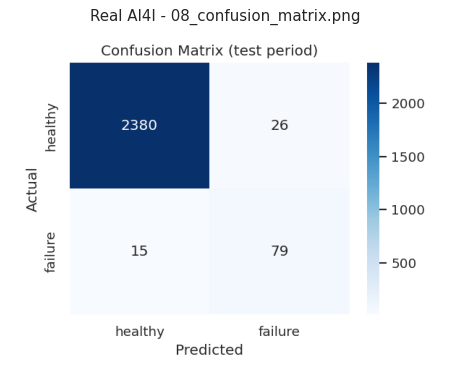

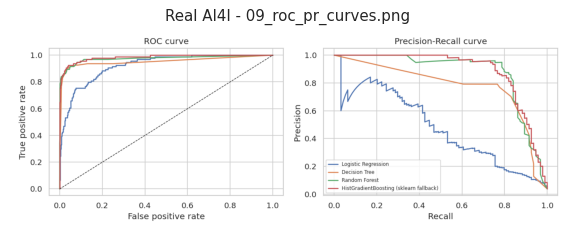

In [5]:
for f in ['08_confusion_matrix.png', '09_roc_pr_curves.png']:
    img = plt.imread('../reports/ai4i_real/figures/' + f)
    plt.figure(figsize=(8,5)); plt.imshow(img); plt.axis('off'); plt.title('Real AI4I - ' + f); plt.show()